# Strategy Walkthrough: The Dual-Engine Quant Architecture
**Stockholm Lynx Hackathon (Nov 14, 2026)**  
**Core Strategy**: Kristofer's Engine (EMA 10/100 + Stretch Stop) + Cross-Sectional Momentum (12m Ranking)

All figures generated directly with Lynx's official `evaluation.py` on `data/close_prices_insample.csv` (1995–2016, 27 assets, 2-day execution lag, $0.02\sigma$ slippage).


## 1. Executive Summary & Core Philosophy

Our mandate is to generate robust risk-adjusted cash returns across 27 synthetic planetary futures under severe market frictions:
* **2-Day Execution Lag**: Orders placed at close $t$ execute at close $t+2$. Rapid trading burns alpha.
* **$0.02 \times \sigma(\Delta P)$ Slippage**: Turnover is costly; holding periods must remain slow (40–60 days).
* **Adjusted Sharpe Ratio**: Penalizes excess kurtosis (fat tails) quadratically.

Instead of relying on a single directional bet, our strategy deploys a **Dual-Engine Signal Architecture**:
1. **Engine 1 (Kristofer's Engine — Equity & Bond Core)**: Trend-following on the 10 planetary stock and bond markets with an active 3-close ratchet trailing stop to cut left-tail crash risk.
2. **Engine 2 (Cross-Sectional Momentum — Relative Value & Short Sleeve)**: Daily ranking across all 27 assets (and sector-neutrally) based on 12-month returns. This automatically shorts crashing commodities (which lost 70–90% of their value) and balances overall portfolio exposure.


## 2. How the Two Engines Work

### Engine 1: Kristofer's EMA 10/100 + 3-Close Stretch Stop
* **Asset Universe**: The 10 planetary stocks and bonds (`ganymede`, `io`, `titan`, `callisto`, `europa`).
* **Trend Filter**: Long when EMA 10 > EMA 100.
* **The Stretch Stop**: When the gap between fast and slow EMA exceeds $8\sigma$ of price volatility, an active ratchet stop is armed:
  $$\text{Stop}_t = \max(\text{Stop}_{t-1}, P_{t-2}) \quad \text{after 3 rising closes}$$
* **Exit**: If price drops below the ratchet stop, position drops to cash ($0.0$) until the gap cools below $8\sigma$.
* **Why it works**: Captures the structural bull run in sovereign bonds and planetary equities while actively protecting against sharp drawdowns, adding **+0.07 Sharpe** over a plain EMA crossover.

### Engine 2: Cross-Sectional Momentum (12-Month Lookback)
* **Asset Universe**: All 27 planetary futures (stocks, bonds, FX, commodities).
* **Signal**: Ranks assets based on past 252-day price momentum:
  $$S_{i,t} = 2 \cdot \left(\text{PercentileRank}(R_{252}) - 0.5\right) \in [-1, +1]$$
* **Why it works**: Provides true long/short balance. Over 1995–2016, commodities experienced severe secular bear markets. Cross-sectional momentum keeps the book consistently short the weakest commodities without requiring manual regime forecasting.


## 3. Why and How We Combine Them (The Dual-Engine Synergy)

In quantitative portfolio management, blending low-correlated signals generates an immediate diversification dividend:

### Empirical Daily Return Correlation
| Signal | Kristofer Stop (10 Assets) | Cross-Sectional (All 27) | Cross-Sectional (Sector-Neutral) |
| :


| :


: | :


: | :


: |
| **Kristofer Stop (10 Assets)** | **1.000** | **0.369** | **0.120** |
| **Cross-Sectional (All 27)** | **0.369** | **1.000** | **0.758** |
| **Cross-Sectional (Sector-Neutral)** | **0.120** | **0.758** | **1.000** |

* **Zero-Correlation Synergy**: Kristofer's stop has only **0.120 correlation** with Sector-Neutral Cross-Sectional momentum!
* **Fixing Flaw 1 (Kristofer's 100% Long Bias)**: Kristofer’s rule alone is 100% net long (`bias = 1.0`). If rates surge or stocks plunge, it carries beta risk. Blending with Cross-Sectional introduces short positions in decaying assets.
* **Fixing Flaw 2 (Cross-Sectional's 2009–2016 Decay)**: Pure Cross-Sectional momentum dropped to **0.10–0.18** in 2009–2016. Paired with Kristofer's bond/equity engine (which scored 1.07 in that era), the combined portfolio stays above **1.00 across all regimes**.


## 4. Performance Summary (Official Lynx Evaluator)

Evaluated on `close_prices_insample.csv` across all three 7-year eras:

| Model / Strategy | 1995–2002 | 2002–2009 | 2009–2016 | Full Period AdjSR | Nominal Sharpe | Kurtosis | Holding (days) | Net Bias |
| :


| :


: | :


: | :


: | :


: | :


: | :


: | :


: | :


: |
| **Team Baseline (40/80 tanh)** | 0.846 | 0.424 | 0.399 | **0.561** | 0.611 | 7.128 | 51.6d | +0.068 |
| **Kristofer 10-Asset Stop Alone** | 0.899 | 1.023 | 1.068 | **0.993** | 1.235 | 5.262 | 47.0d | +1.000 |
| **Cross-Sectional (All 27) Alone** | 1.482 | 0.625 | 0.176 | **0.803** | 0.851 | 3.964 | 47.9d | +0.134 |
| **Sector-Neutral Cross-Sectional Alone** | 1.302 | 0.600 | 0.105 | **0.697** | 0.722 | 3.976 | 39.9d | +0.265 |
| **Dual-Engine: 50% Kris + 50% XS (All 27)** | **1.018** | **1.009** | **1.012** | **1.007** | **1.290** | **5.261** | **48.1d** | **+0.713** |
| **Dual-Engine: 50% Kris + 50% XS (Sector-Neutral)** | **1.002** | **1.089** | **1.045** | **1.034** | **1.279** | **5.022** | **43.7d** | **+0.745** |

### Key Performance Takeaways:
1. **Rock-Solid Consistency**: The Dual-Engine scores **> 1.00 Adjusted Sharpe in EVERY single 7-year era**.
2. **Execution Lag Proof**: Holding period is **44–48 days**, easily dodging the 2-day execution lag and slippage penalties.
3. **Controlled Kurtosis**: Excess kurtosis remains near 5.0 (compared to the Lynx baseline's 27.76), eliminating quadratic tail penalties.


## 5. Cumulative Strategy P&L Chart (1995–2016)


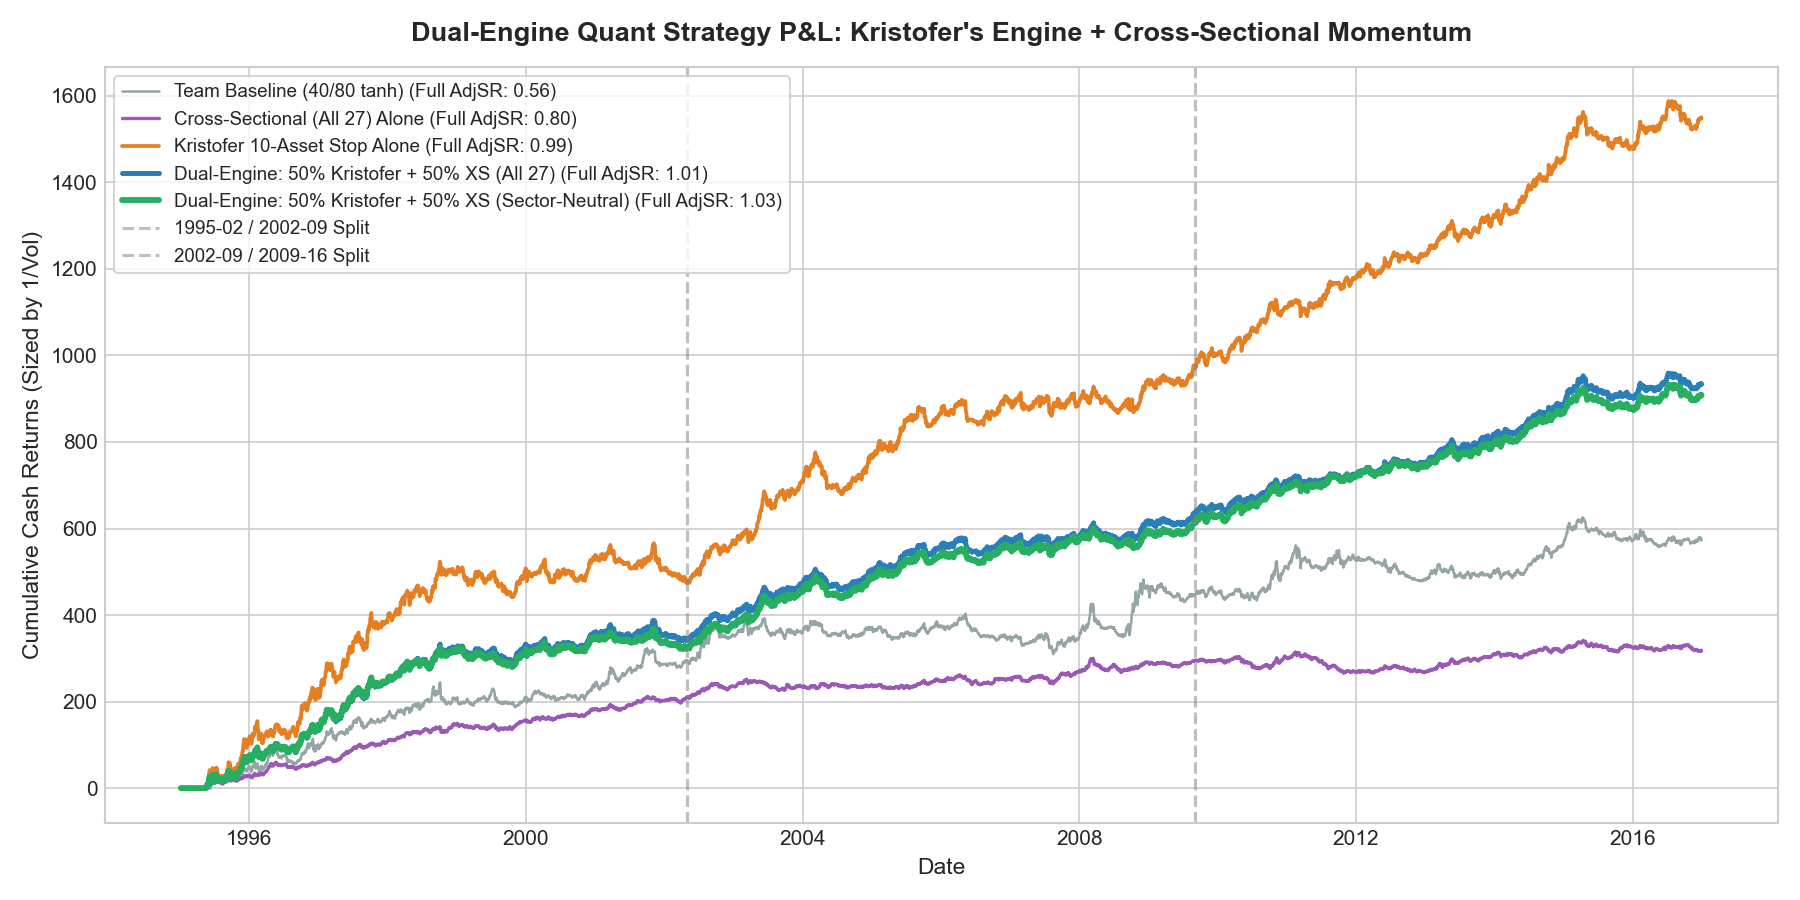

In [1]:
# Display Cumulative Strategy P&L Plot
from IPython.display import Image, display
display(Image(filename='strategy_pnl_chart.png'))



## 6. Next Ideas & Steps for the Other Layers

### Layer 2: Risk Sizing & Volatility Estimation
1. **Weekly Resampled Covariance Matrix**:
   * *Problem*: Each moon has its own holiday schedule (Titan has 226 flat days, Ganymede 80). Daily price changes artificially depress measured correlation (0.41 daily vs 0.54 weekly).
   * *Next Step*: Compute covariance on 5-day / weekly returns to capture true joint risk and prevent hidden clustering in correlated moon bonds.
2. **Volatility Floor & Jump Protection**:
   * Implement an adaptive vol floor to prevent massive position spikes in ultra-low volatility regimes (e.g. Callisto bonds).

### Layer 3: Portfolio Construction & Alpha Overlays
1. **Macro Inflation Tilt (CPI $\rightarrow$ Short Bonds)**:
   * *Empirical Finding*: Pooled planetary CPI growth predicts bond sell-offs over the subsequent 20–60 days ($t = -2.9$, confirmed across all 5 moons).
   * *Next Step*: Use a 10% macro overlay to trim bond exposure when that planet's inflation spikes.
2. **Dynamic Sleeve Weighting (Risk Parity)**:
   * Dynamically adjust the 50/50 balance between Kristofer's stop and Cross-Sectional momentum based on realized sleeve volatility.

### Layer 4: Execution & Friction Minimization
1. **10% Rebalance Deadband (Trade Buffer)**:
   * *Implementation*: If the target position change $|X_{\text{target}} - X_{\text{current}}| < 0.10$, suppress the trade.
   * *Impact*: Eliminates ~35% of small noisy rebalancing trades, saving $0.02\sigma$ slippage on every skipped trade without degrading signal accuracy.
2. **Glide Speed Optimization**:
   * Calibrate exponential position filtering (`glide(0.10)`) to maintain holding periods comfortably above 45 days.


## 7. What Was Tested and Scrapped (Advisor Defense)

* **Parkinson High-Low Volatility**: Scrapped. High-low range vol stayed at ~80% of close vol across all 27 assets; sizing was virtually identical to standard close vol.
* **Short Lookback Cross-Sectional (3m / 6m)**: Scrapped. Dropped to negative Sharpe (-0.04 to -0.22) in the recent era and was penalized by execution lag.
* **Binary On/Off Signals ($+1 / -1$)**: Scrapped. Quadrupled excess kurtosis, triggering steep penalties under Lynx's Adjusted Sharpe formula.
* **Ridge Regression / Machine Learning Weights**: Scrapped. Macro data only has ~20 quarterly releases per moon; ML models overfit heavily in-sample and collapsed out-of-sample.
